# Chapitre 3 - Cours 4 : Classer des modèles par comparaisons (Elo, Bradley-Terry)

Ce dernier notebook de cours couvre la section *Ranking Models with Comparative
Evaluation* : évaluation ponctuelle contre comparative, algorithmes de classement (Elo,
Bradley-Terry), et les trois difficultés que le livre détaille dans *Challenges of
Comparative Evaluation* (passage à l'échelle et transitivité, standardisation et contrôle
qualité, passage du relatif à l'absolu), avant *The Future of Comparative Evaluation*.
Tout est simulé en numpy : aucune donnée réelle d'arène n'est nécessaire pour comprendre
les mécanismes.

**Plan.**

1. Évaluation ponctuelle ou comparative, et l'architecture d'une arène.
2. Le modèle de Bradley-Terry et la formule d'Elo.
3. Elo en pratique : trajectoires, facteur K, sensibilité à l'ordre des matchs.
4. Bradley-Terry par maximum de vraisemblance (algorithme MM) et intervalles bootstrap.
5. La table 3-6 du livre : classement et intransitivité.
6. Quand la transitivité casse : simulation pierre-feuille-ciseaux.
7. Combien de comparaisons faut-il ? Croissance quadratique et appariement adaptatif.
8. Du comparatif à l'absolu : que signifie un taux de victoire de 51 % ?

In [1]:
import math
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau

from aie import ch03_evaluation as ev
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)

## 1. Évaluation ponctuelle ou comparative (section *Ranking Models with Comparative Evaluation*)

Souvent, on évalue des modèles non pour leur score mais pour savoir **lequel choisir** :
on veut un classement. Deux voies :

- **ponctuelle** (« pointwise ») : chaque modèle est noté séparément (benchmark, échelle
  de Likert), puis on trie les notes ;
- **comparative** : on présente des réponses côte à côte et l'on demande laquelle est
  meilleure ; un algorithme transforme ces duels en classement.

Pour des qualités subjectives, comparer est plus facile que noter (dire laquelle de deux
chansons on préfère est plus simple que donner une note à chacune). C'est le principe de
Chatbot Arena (LMSYS) : un utilisateur écrit un prompt, reçoit les réponses de deux
modèles anonymes, vote, et les noms ne sont révélés qu'après. À ne pas confondre avec un
test A/B, où chaque utilisateur ne voit qu'une seule variante.

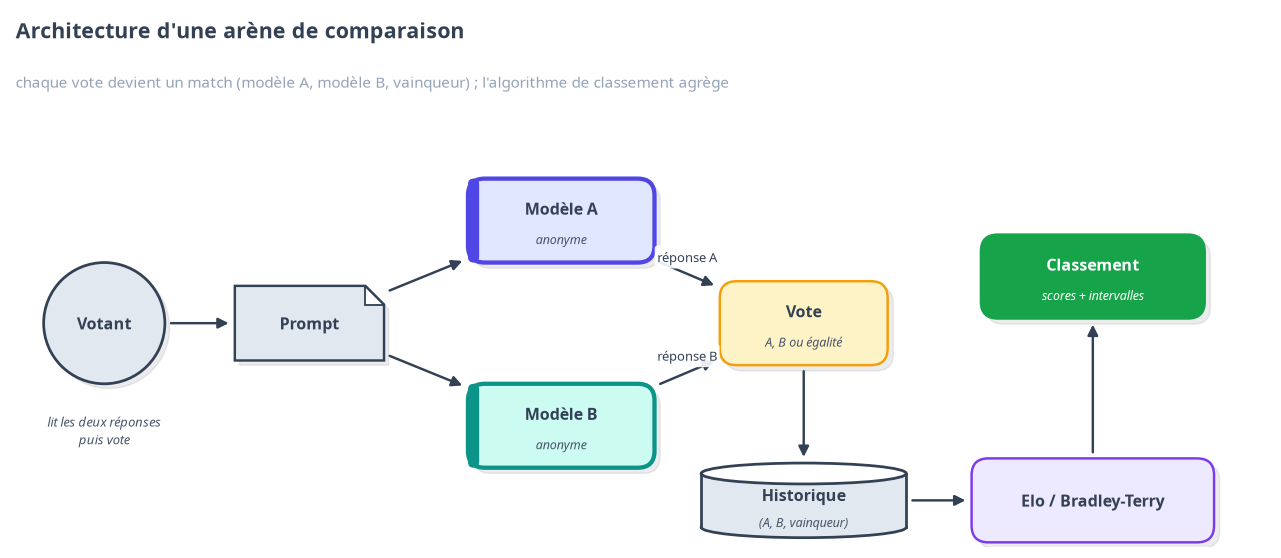

In [2]:
d = Diagram(13.5, 4.8, title="Architecture d'une arène de comparaison",
            subtitle="chaque vote devient un match (modèle A, modèle B, vainqueur) ; l'algorithme de classement agrège")
d.box("u", 1.0, 2.4, "Votant", color=SLATE, kind="user", w=1.3)
d.box("p", 3.2, 2.4, "Prompt", color=SLATE, kind="doc", w=1.6, h=0.8)
d.box("ma", 5.9, 3.5, "Modèle A", sub="anonyme", color=INDIGO, kind="model", w=2.0)
d.box("mb", 5.9, 1.3, "Modèle B", sub="anonyme", color=TEAL, kind="model", w=2.0)
d.box("v", 8.5, 2.4, "Vote", sub="A, B ou égalité", color=AMBER, w=1.8)
d.box("log", 8.5, 0.5, "Historique", sub="(A, B, vainqueur)", color=SLATE, kind="db", w=2.2, h=0.8)
d.box("algo", 11.6, 0.5, "Elo / Bradley-Terry", color=VIOLET, w=2.6)
d.box("lb", 11.6, 2.9, "Classement", sub="scores + intervalles", color=GREEN, w=2.4, filled=True)
d.arrow("u", "p"); d.arrow("p", "ma"); d.arrow("p", "mb")
d.arrow("ma", "v", "réponse A"); d.arrow("mb", "v", "réponse B")
d.note(1.0, 1.25, "lit les deux réponses\npuis vote", fontsize=8.5)
d.arrow("v", "log"); d.arrow("log", "algo"); d.arrow("algo", "lb")
d.show()

Le livre insiste sur une mise en garde : **toutes les questions ne relèvent pas de la
préférence**. « Y a-t-il un lien entre ondes des téléphones et tumeurs ? » relève de la
justesse, pas d'un vote ; et un utilisateur qui pose une question de maths dont il ignore
la réponse ne sait pas choisir entre deux réponses. Le vote par préférence fonctionne
quand les votants maîtrisent le sujet.

> **À retenir.** L'évaluation comparative remplace la note absolue par des duels,
> plus faciles à juger pour des qualités subjectives. Un algorithme de classement
> transforme l'historique des duels en scores.

## 2. Le modèle de Bradley-Terry et la formule d'Elo

**Modèle de Bradley-Terry (1952).** Chaque modèle $i$ a une force $s_i$ et
$$P(i \text{ bat } j) = \frac{e^{s_i}}{e^{s_i} + e^{s_j}} = \sigma(s_i - s_j),$$
où $\sigma$ est la fonction logistique. Seules les **différences** de forces comptent.

**Elo** (échecs, années 1960) utilise la même forme avec une autre unité :
$$E_A = P(A \text{ bat } B) = \frac{1}{1 + 10^{(R_B - R_A)/400}}.$$
Avec $s = R \ln 10 / 400$, c'est exactement Bradley-Terry : 400 points d'écart
correspondent à une cote de 10 contre 1 (probabilité $10/11 \approx 91\,\%$).

**La mise à jour d'Elo est une descente de gradient stochastique.** Après un match de
résultat $S \in \{0, \tfrac12, 1\}$, Elo fait $R_A \leftarrow R_A + K(S - E_A)$. Or la
log-vraisemblance du résultat, $\ell = S\log E_A + (1-S)\log(1-E_A)$, a pour dérivée
$\partial \ell / \partial R_A = (S - E_A)\ln 10/400$. La règle d'Elo est donc un pas de
gradient de taille $\eta = 400K/\ln 10$ sur **un seul match** : un apprentissage en
ligne à pas constant. Deux conséquences, que l'on va observer : le résultat dépend de
l'**ordre** des matchs, et les scores ne convergent jamais vraiment (ils fluctuent avec
une amplitude liée à $K$). Elo conserve aussi la somme des scores (ce que gagne A, B le
perd).

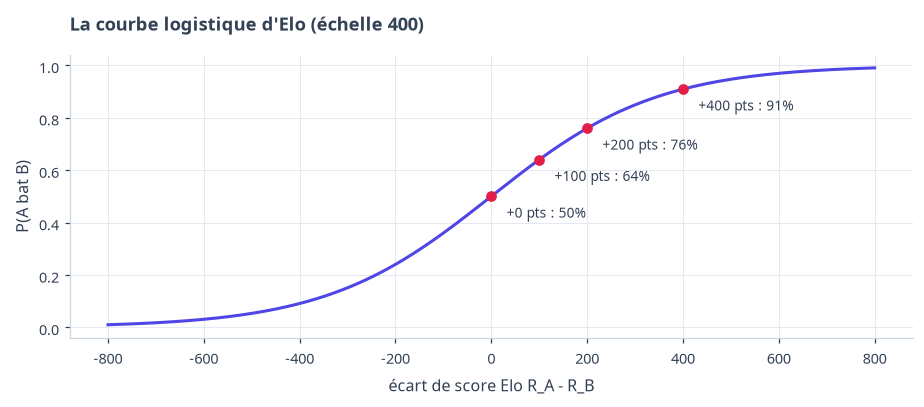

In [3]:
diff = np.linspace(-800, 800, 400)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(diff, [ev.elo_expected(x, 0) for x in diff], color=INDIGO)
for x in [0, 100, 200, 400]:
    p = ev.elo_expected(x, 0)
    ax.scatter([x], [p], color=ROSE, zorder=3)
    ax.annotate(f"+{x} pts : {p:.0%}", (x, p), (10, -14), textcoords="offset points", fontsize=9)
ax.set_xlabel("écart de score Elo R_A - R_B"); ax.set_ylabel("P(A bat B)")
ax.set_title("La courbe logistique d'Elo (échelle 400)")
plt.tight_layout(); plt.show()

> **À retenir.** Elo et Bradley-Terry reposent sur le même modèle logistique des
> différences de forces. Bradley-Terry estime les forces par maximum de vraisemblance sur
> tous les matchs ; Elo les met à jour match après match, comme un gradient stochastique.

## 3. Elo en pratique : trajectoires, facteur K et sensibilité à l'ordre

Simulons cinq modèles de forces connues (en points Elo : 1 250, 1 150, 1 120, 1 000, 900 ;
les modèles 2 et 3 sont proches) et 3 000 matchs entre paires tirées au hasard.

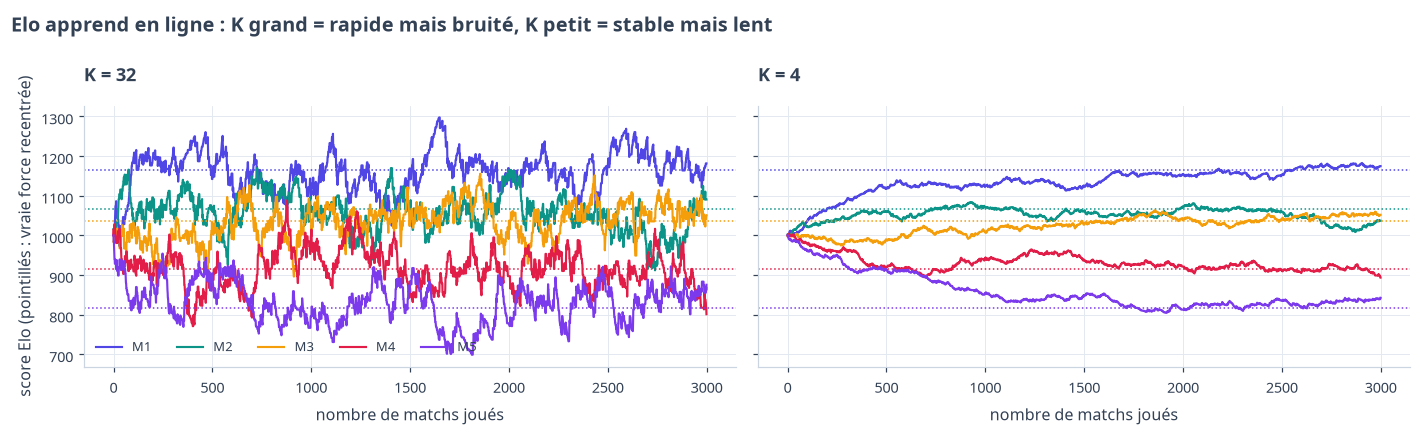

In [4]:
vrai = np.array([1250, 1150, 1120, 1000, 900.0])
noms = [f"M{i + 1}" for i in range(5)]
P = ev.prob_matrix_from_elo(vrai)
matchs = ev.simulate_matches(P, 3000, np.random.default_rng(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, K in zip(axes, [32, 4]):
    _, hist = ev.elo_ratings(matchs, 5, k=K, history=True)
    for i in range(5):
        ax.plot(hist[:, i], color=COLORS[i], lw=1.4, label=noms[i])
        ax.axhline(vrai[i] - vrai.mean() + 1000, color=COLORS[i], ls=":", lw=1)
    ax.set_title(f"K = {K}")
    ax.set_xlabel("nombre de matchs joués")
axes[0].set_ylabel("score Elo (pointillés : vraie force recentrée)")
axes[0].legend(ncol=5, loc="lower left", fontsize=8.5)
finish(fig, "Elo apprend en ligne : K grand = rapide mais bruité, K petit = stable mais lent")
plt.show()

Avec $K = 32$, les scores atteignent vite le bon ordre de grandeur mais oscillent en
permanence (M2 et M3 échangent régulièrement leurs places) ; avec $K = 4$, ils sont plus
stables mais mettent des centaines de matchs à converger. **Sensibilité à l'ordre** :
rejouons exactement les mêmes 3 000 matchs dans 200 ordres aléatoires différents.

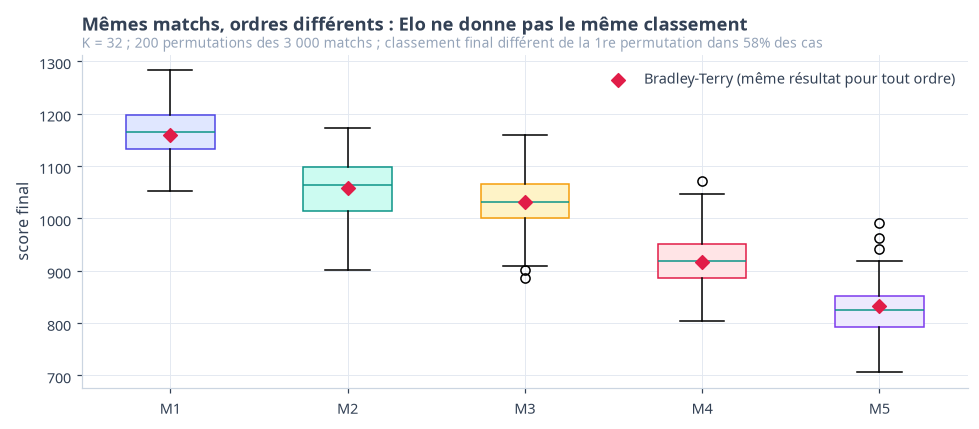

In [5]:
finals = np.array([ev.elo_ratings([matchs[i] for i in np.random.default_rng(s).permutation(len(matchs))], 5, k=32)
                   for s in range(200)])
bt_elo = ev.bt_to_elo(ev.bradley_terry(ev.win_matrix(matchs, 5)))
rang_change = np.mean([np.argsort(-f).tolist() != np.argsort(-finals[0]).tolist() for f in finals])
fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot([finals[:, i] for i in range(5)], tick_labels=noms, patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], COLORS):
    patch.set_facecolor(LIGHT[c]); patch.set_edgecolor(c)
ax.scatter(range(1, 6), bt_elo, marker="D", color=ROSE, zorder=4, s=40, label="Bradley-Terry (même résultat pour tout ordre)")
ax.set_ylabel("score final")
ax.set_title("Mêmes matchs, ordres différents : Elo ne donne pas le même classement")
subtitle(ax, f"K = 32 ; 200 permutations des 3 000 matchs ; classement final différent de la 1re permutation "
             f"dans {rang_change:.0%} des cas")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Les **mêmes** données produisent des scores Elo différents selon l'ordre de traitement,
au point d'inverser M2 et M3 dans une part notable des cas. C'est précisément la raison
invoquée par LMSYS pour abandonner Elo au profit de Bradley-Terry (sensibilité à l'ordre
des évaluateurs et des prompts). Elo reste pertinent quand les forces **évoluent** dans
le temps (un joueur d'échecs progresse) ; un modèle figé n'évolue pas, et l'on préfère
une estimation globale.

> **À retenir.** Elo est un estimateur en ligne : son résultat dépend de l'ordre des
> matchs et du facteur K. Pour des modèles figés, l'estimation par maximum de
> vraisemblance (Bradley-Terry) est plus adaptée.